In [2]:
import matplotlib.pyplot as plt
import numpy as np

import utils
from graph_builder import PollutionGraph
from pathfinding import AStarAlgorithm, DijkstraAlgorithm, BFSAlgorithm

print("Imports successful!")

Imports successful!


In [3]:
mock_data = [
    {'latitude': 44.4268, 'longitude': 26.1025, 'pm10': 30, 'pm2_5': 15, 'no2': 20},
    {'latitude': 44.4320, 'longitude': 26.1050, 'pm10': 45, 'pm2_5': 22, 'no2': 35},
    {'latitude': 44.4380, 'longitude': 26.1100, 'pm10': 25, 'pm2_5': 12, 'no2': 18},
    {'latitude': 44.4400, 'longitude': 26.1150, 'pm10': 50, 'pm2_5': 28, 'no2': 40},
    {'latitude': 44.4450, 'longitude': 26.1200, 'pm10': 35, 'pm2_5': 18, 'no2': 25},
]

print(f"Created {len(mock_data)} pollution data points")
for i, point in enumerate(mock_data):
    print(f"  Point {i+1}: ({point['latitude']}, {point['longitude']}) - PM10: {point['pm10']}")


Created 5 pollution data points
  Point 1: (44.4268, 26.1025) - PM10: 30
  Point 2: (44.432, 26.105) - PM10: 45
  Point 3: (44.438, 26.11) - PM10: 25
  Point 4: (44.44, 26.115) - PM10: 50
  Point 5: (44.445, 26.12) - PM10: 35


In [4]:
print("Building pollution graph...")
resolution = 0.005  # Larger resolution for faster testing (500m)
graph = PollutionGraph(resolution=resolution)
graph.build_from_pollution_data(mock_data)

print(f"\nGraph statistics:")
print(f"  Total nodes: {len(graph.nodes)}")
print(f"  Total edges: {sum(len(v) for v in graph.edges.values())}")
print(f"  Resolution: {resolution} (~{resolution*111:.0f}m)")


Building pollution graph...
Building graph with resolution 0.005...
Grid dimensions: 30 x 50
Populated 5 cells with real data
Interpolating missing values...
Interpolated 1465 cells
Building edges...
Graph ready: 1470 nodes, 11290 edges

Graph statistics:
  Total nodes: 1470
  Total edges: 11290
  Resolution: 0.005 (~1m)


In [6]:
start_lat, start_lon = 44.4268, 26.1025
goal_lat, goal_lon = 44.4450, 26.1200

start = utils.get_grid_cell(start_lat, start_lon, resolution)
goal = utils.get_grid_cell(goal_lat, goal_lon, resolution)


print(f"Start: ({start_lat}, {start_lon}) -> Cell {start}")
print(f"Goal: ({goal_lat}, {goal_lon}) -> Cell {goal}")
print(f"Manhattan distance (cells): {abs(goal[0]-start[0]) + abs(goal[1]-start[1])}")

if start not in graph.nodes:
    print(f"ERROR: Start cell {start} not in graph!")
else:
    print(f"Start cell verified in graph")

if goal not in graph.nodes:
    print(f"ERROR: Goal cell {goal} not in graph!")
else:
    print(f"Goal cell verified in graph")

Start: (44.4268, 26.1025) -> Cell (8885, 5220)
Goal: (44.445, 26.12) -> Cell (8889, 5224)
Manhattan distance (cells): 8
Start cell verified in graph
Goal cell verified in graph


In [7]:
print("\nTesting A* with different heuristics...")

heuristics = {
    "Haversine": utils.haversine_heuristic,
    "Euclidean": utils.euclidean_heuristic,
    "Manhattan": utils.manhattan_heuristic,
}

astar_results = {}
for name, heuristic_fn in heuristics.items():
    print(f"\nRunning A* with {name} heuristic...")
    astar = AStarAlgorithm(graph, heuristic_fn=heuristic_fn)
    result = astar.find_path(start, goal)
    
    if 'error' in result:
        print(f"  FAILED: {result['error']}")
    else:
        stats = astar.get_stats()
        astar_results[name] = stats
        print(f"  SUCCESS!")
        print(f"    Nodes explored: {stats['nodes_explored']}")
        print(f"    Path length: {stats['path_length']}")
        print(f"    Total cost: {stats['total_cost']:.4f}")



Testing A* with different heuristics...

Running A* with Haversine heuristic...
  SUCCESS!
    Nodes explored: 6
    Path length: 5
    Total cost: 2.9572

Running A* with Euclidean heuristic...
  SUCCESS!
    Nodes explored: 84
    Path length: 5
    Total cost: 2.9572

Running A* with Manhattan heuristic...
  SUCCESS!
    Nodes explored: 84
    Path length: 5
    Total cost: 2.9572


In [8]:
print("\nTesting Dijkstra...")

dijkstra = DijkstraAlgorithm(graph)
result_dijkstra = dijkstra.find_path(start, goal)

if 'error' in result_dijkstra:
    print(f"FAILED: {result_dijkstra['error']}")
else:
    stats_dijkstra = dijkstra.get_stats()
    print(f"SUCCESS!")
    print(f"  Nodes explored: {stats_dijkstra['nodes_explored']}")
    print(f"  Path length: {stats_dijkstra['path_length']}")
    print(f"  Total cost: {stats_dijkstra['total_cost']:.4f}")


Testing Dijkstra...
SUCCESS!
  Nodes explored: 104
  Path length: 5
  Total cost: 2.9572


In [9]:
print("\nTesting BFS...")

bfs = BFSAlgorithm(graph)
result_bfs = bfs.find_path(start, goal)

if 'error' in result_bfs:
    print(f"FAILED: {result_bfs['error']}")
else:
    stats_bfs = bfs.get_stats()
    print(f"SUCCESS!")
    print(f"  Nodes explored: {stats_bfs['nodes_explored']}")
    print(f"  Path length: {stats_bfs['path_length']}")


Testing BFS...
SUCCESS!
  Nodes explored: 81
  Path length: 6


In [10]:
print("\nCreating comparison visualization...")


import pandas as pd

comparison_data = []

# A* variants
for name, stats in astar_results.items():
    comparison_data.append({
        'Algorithm': f'A* ({name})',
        'Nodes Explored': stats['nodes_explored'],
        'Path Length': stats['path_length'],
        'Total Cost': f"{stats['total_cost']:.4f}"
    })

# Dijkstra
if 'error' not in result_dijkstra:
    comparison_data.append({
        'Algorithm': 'Dijkstra',
        'Nodes Explored': stats_dijkstra['nodes_explored'],
        'Path Length': stats_dijkstra['path_length'],
        'Total Cost': f"{stats_dijkstra['total_cost']:.4f}"
    })

# BFS
if 'error' not in result_bfs:
    comparison_data.append({
        'Algorithm': 'BFS',
        'Nodes Explored': stats_bfs['nodes_explored'],
        'Path Length': stats_bfs['path_length'],
        'Total Cost': 'N/A'
    })

df = pd.DataFrame(comparison_data)
print(df.to_string(index=False))


Creating comparison visualization...
     Algorithm  Nodes Explored  Path Length Total Cost
A* (Haversine)               6            5     2.9572
A* (Euclidean)              84            5     2.9572
A* (Manhattan)              84            5     2.9572
      Dijkstra             104            5     2.9572
           BFS              81            6        N/A



Creating A* animation...
Saved: astar_visualization.png


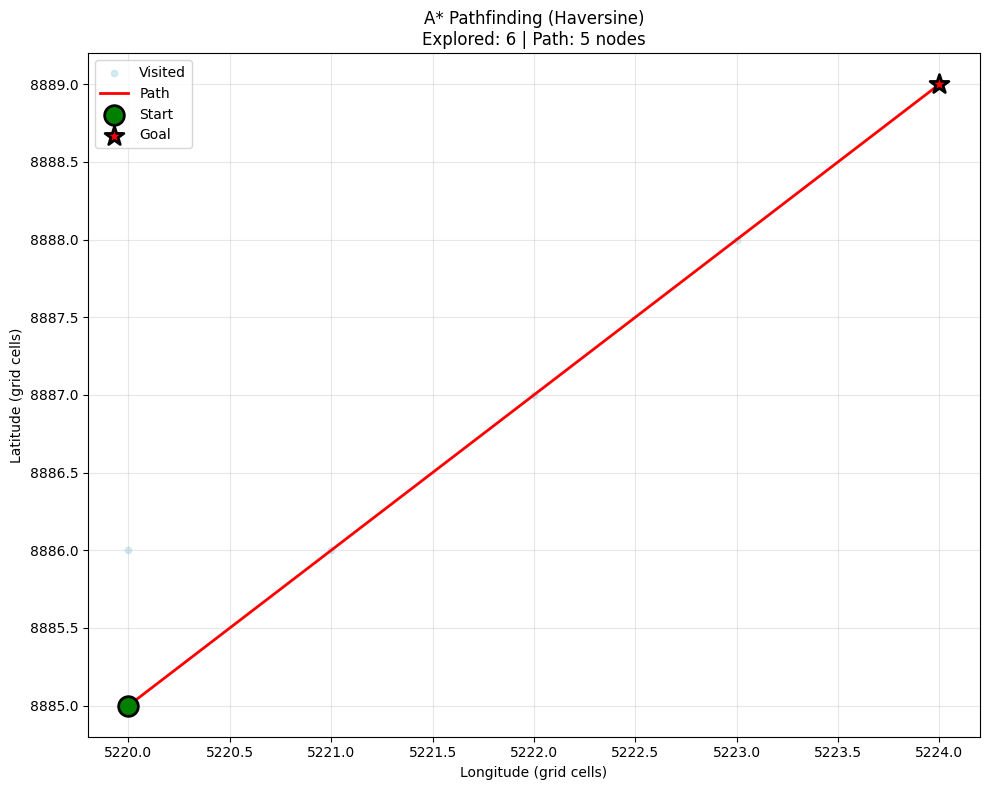

In [11]:
print("\nCreating A* animation...")
astar_best = AStarAlgorithm(graph, heuristic_fn=utils.haversine_heuristic)
result_best = astar_best.find_path(start, goal)

if 'error' not in result_best:
    path = result_best['path']
    visited = [v['cell'] for v in result_best['visited_nodes']]
    
    fig, ax = plt.subplots(figsize=(10, 8))
    
    # Plot visited nodes
    if visited:
        visited_x = [c[1] for c in visited]
        visited_y = [c[0] for c in visited]
        ax.scatter(visited_x, visited_y, c='lightblue', s=20, alpha=0.5, label='Visited')
    
    # Plot path
    if path:
        path_x = [c[1] for c in path]
        path_y = [c[0] for c in path]
        ax.plot(path_x, path_y, 'r-', linewidth=2, label='Path')
    
    # Plot start and goal
    ax.scatter([start[1]], [start[0]], c='green', s=200, marker='o', 
              label='Start', zorder=5, edgecolors='black', linewidths=2)
    ax.scatter([goal[1]], [goal[0]], c='red', s=200, marker='*', 
              label='Goal', zorder=5, edgecolors='black', linewidths=2)
    
    ax.set_title(f'A* Pathfinding (Haversine)\nExplored: {len(visited)} | Path: {len(path)} nodes')
    ax.set_xlabel('Longitude (grid cells)')
    ax.set_ylabel('Latitude (grid cells)')
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('astar_visualization.png', dpi=150)
    print("Saved: astar_visualization.png")
    plt.show()
else:
    print(f"Cannot visualize: {result_best['error']}")


TypeError: 'NoneType' object is not subscriptable

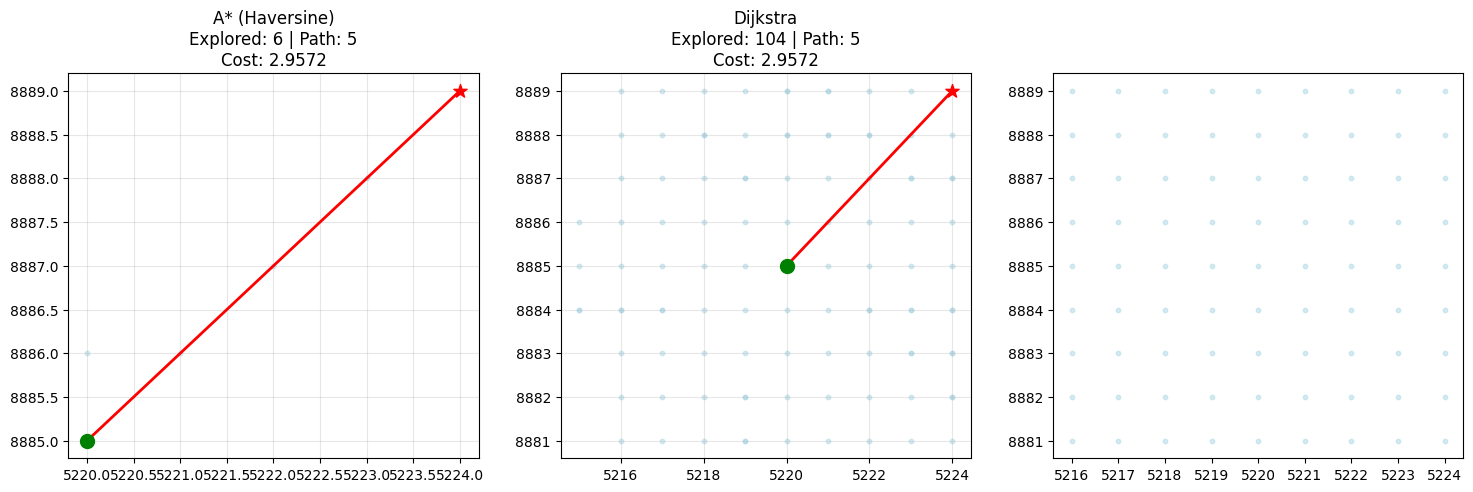

In [12]:
algorithms = [
    ("A* (Haversine)", AStarAlgorithm(graph, heuristic_fn=utils.haversine_heuristic)),
    ("Dijkstra", DijkstraAlgorithm(graph)),
    ("BFS", BFSAlgorithm(graph))
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, (name, algo) in enumerate(algorithms):
    ax = axes[idx]
    result = algo.find_path(start, goal)
    
    if 'error' in result:
        ax.text(0.5, 0.5, f'{name}\nFAILED', 
               ha='center', va='center', fontsize=14)
        ax.set_title(name)
        continue
    
    path = result['path']
    visited = [v['cell'] for v in result['visited_nodes']]
    
    # Plot visited
    if visited:
        v_x = [c[1] for c in visited]
        v_y = [c[0] for c in visited]
        ax.scatter(v_x, v_y, c='lightblue', s=10, alpha=0.5)
    
    # Plot path
    if path:
        p_x = [c[1] for c in path]
        p_y = [c[0] for c in path]
        ax.plot(p_x, p_y, 'r-', linewidth=2)
    
    # Start and goal
    ax.scatter([start[1]], [start[0]], c='green', s=100, marker='o', zorder=5)
    ax.scatter([goal[1]], [goal[0]], c='red', s=100, marker='*', zorder=5)
    
    # Title with stats
    stats = algo.get_stats()
    title = f"{name}\n"
    title += f"Explored: {stats['nodes_explored']} | Path: {stats['path_length']}"
    if 'total_cost' in stats:
        title += f"\nCost: {stats['total_cost']:.4f}"
    ax.set_title(title)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('algorithm_comparison.png', dpi=150)
print("Saved: algorithm_comparison.png")
plt.show()